# Chip Pipeline

1. Crops the orthomosaic into smaller tiles
2. Identifies buildings or candidate structures inside the tiles
3. Discards tiles that do not contain buildings or structures
4. Creates chips from tiles with buildings

In [1]:
!pip install -q git+https://github.com/facebookresearch/segment-anything.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## Packages

In [2]:
import geopandas as gpd
import geemap
import pandas as pd
# import rioxarray as rxr
import rasterio
from rasterio.plot import show
from rasterio.windows import Window
from rasterio.windows import bounds as window_bounds
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from scipy import ndimage as ndi
from skimage.morphology import remove_small_objects, remove_small_holes
from matplotlib.colors import ListedColormap
import pysal
from affine import Affine
# import contextily as ctx
import xarray as xr
import folium
import os
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from shapely.geometry import box
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import torch
from scipy import ndimage as ndi
from skimage.morphology import remove_small_objects, remove_small_holes
from skimage.segmentation import find_boundaries
from tqdm.auto import tqdm
from segment_anything import sam_model_registry, SamPredictor, SamAutomaticMaskGenerator
from shapely.geometry import box
from shapely.ops import unary_union
warnings.filterwarnings("ignore")

# 1. Loading data

Unzipping VM8 data from Google Drive.

In [3]:
!unzip -q "/content/drive/MyDrive/remoteclip_data/VM8.zip" -d /content/data

Unzipping data inside VM8.zip into data.

In [4]:
vm8_path= "/content/data/VM8/"
vm8_files = ['terra_dem.rar', 'terra_dom.rar', 'terra_dsm.rar', 'terra_las.rar']
dest = "/content/data/VM8/"

for p in vm8_files:
  path = dest + p.rstrip('.rar')
  os.makedirs(path, exist_ok=True)

Decompressing .rars

In [5]:
!apt-get -qq install unrar

In [ ]:
for p in vm8_files:
    rar_path = vm8_path + p
    !unrar x -idq "{rar_path}" "{dest}"

# Variables

In [ ]:
DOM_PATH = "/content/data/VM8/terra_dom/dom.tif"
DEM_PATH = "/content/data/VM8/terra_dem/dem.tif"
DSM_PATH = "/content/data/VM8/terra_dsm/dsm.tif"

TILE = 500                # tile size in px
OVERLAP = 0               # px of overlap between neighboring tiles
EDGE = "shift"            # "shift": last row/col moves inward so every tile is exactly TILE x TILE (overlaps its neighbor)
                          # "partial": no overlap, last row/col is smaller (8 px wide here)
MIN_VALID = 0.7           # threshold for valid pixels in tile
F = 10                    # overview factor (~0.5 m/px)
HEIGHT_THR = 2.0          # a structure is anything with nDSM > this (m)
MIN_STRUCT_M2 = 2.0       # smallest structure that counts (m²)
NDSM_RANGE = (-20, 250)   # nDSM values outside this range (m) are treated as nodata

# 1. Tile creation and filtering by nDSM

## V3: Memory efficient

We create a class called TileReader.

In [27]:
class TileReader:
    """Reads one window at a time: RGB, validity mask (alpha) and nDSM. Opens files lazily,
    so it is safe to use after fork (e.g. DataLoader workers)."""

    def __init__(self, dom_path, dsm_path, dem_path, resampling=Resampling.bilinear):
        self.paths, self.resampling, self._h = (dom_path, dsm_path, dem_path), resampling, None

    def _open(self):
        if self._h is None:
            ortho = rasterio.open(self.paths[0])
            srcs = [rasterio.open(p) for p in self.paths[1:]]
            vrts = [WarpedVRT(s, crs=ortho.crs, transform=ortho.transform,
                              width=ortho.width, height=ortho.height,
                              resampling=self.resampling,
                              nodata=s.nodata if s.nodata is not None else np.nan)
                    for s in srcs]
            self._h = (ortho, srcs, vrts)
        return self._h

    def __getstate__(self):                           # handles are not picklable; reopen in the new process
        return {**self.__dict__, "_h": None}

    def close(self):
        if self._h:
            ortho, srcs, vrts = self._h
            for d in [*vrts, *srcs, ortho]:
                d.close()
            self._h = None

    def read(self, col_off, row_off, width, height, image=True):
        ortho, _, (dsm, dem) = self._open()
        w = Window(int(col_off), int(row_off), int(width), int(height))
        valid = ortho.read(4, window=w) > 0
        ndsm = (dsm.read(1, window=w, masked=True).astype("float32")
                - dem.read(1, window=w, masked=True).astype("float32")).filled(np.nan)
        ndsm[~valid | (ndsm < NDSM_RANGE[0]) | (ndsm > NDSM_RANGE[1])] = np.nan
        out = {"valid": valid, "ndsm": ndsm}            # ndsm: float32, NaN = no data
        if image:
            out["image"] = ortho.read([1, 2, 3], window=w)    # (3, h, w) uint8
        return out

reader = TileReader(DOM_PATH, DSM_PATH, DEM_PATH)

In [28]:
step = TILE - OVERLAP

with rasterio.open(DOM_PATH) as src:
    H, W, tf, crs, bounds = src.height, src.width, src.transform, src.crs, src.bounds
    res = src.res[0]
    ov = src.read(out_shape=(src.count, H // F, W // F), resampling=Resampling.average)

valid_ov = ov[3] > 127                                   # footprint from alpha
fy, fx = H / valid_ov.shape[0], W / valid_ov.shape[1]    # full-res px per overview px
yy = (np.arange(valid_ov.shape[0]) + 0.5) * fy           # overview pixel centers, in full-res px
xx = (np.arange(valid_ov.shape[1]) + 0.5) * fx

def starts(total, tile, step):
    if EDGE == "partial":
        return list(range(0, total, step))
    if total <= tile:
        return [0]
    s = list(range(0, total - tile + 1, step))
    if s[-1] + tile < total:
        s.append(total - tile)                           # final tile moved inward to reach the edge
    return s

def ov_slice(row_off, col_off, h, w):
    r0, r1 = np.searchsorted(yy, [row_off, row_off + h])
    c0, c1 = np.searchsorted(xx, [col_off, col_off + w])
    return slice(r0, r1), slice(c0, c1)

records = []
for ri, row_off in enumerate(starts(H, TILE, step)):
    for ci, col_off in enumerate(starts(W, TILE, step)):
        w = Window(col_off, row_off, min(TILE, W - col_off), min(TILE, H - row_off))
        v = valid_ov[ov_slice(row_off, col_off, w.height, w.width)]
        records.append(dict(ri=ri, ci=ci, col_off=col_off, row_off=row_off,
                            width=int(w.width), height=int(w.height),
                            valid_frac_ov=v.mean() if v.size else 0.0,
                            geometry=box(*window_bounds(w, tf))))

# Tiles are saved in a GeoDataFrame in the grid variable.

grid = gpd.GeoDataFrame(records, crs=crs)
grid["tile_id"] = grid.index
grid["has_data"] = grid.valid_frac_ov > MIN_VALID
print(len(grid), "tiles in the grid:", grid.ci.max() + 1, "cols x", grid.ri.max() + 1, "rows |",
      int(grid.has_data.sum()), "contain data")

# orthomosaic footprint as a polygon (from the overview alpha)
ov_tf = tf * Affine.scale(fx, fy)
footprint = unary_union([shape(g) for g, _ in
                         shapes(valid_ov.astype("uint8"), mask=valid_ov, transform=ov_tf)]
                        ).simplify(fx * res)

# coverage check: every valid pixel must be covered by at least one tile that has data
count = np.zeros(valid_ov.shape, np.int16)
for t in grid[grid.has_data].itertuples():
    count[ov_slice(t.row_off, t.col_off, t.height, t.width)] += 1
print("bounding box not covered by the grid (m²):",
      round(box(*bounds).difference(unary_union(list(grid.geometry))).area, 4))
print("valid pixels not covered:", int((valid_ov & (count == 0)).sum()))

2700 tiles in the grid: 50 cols x 54 rows | 1110 contain data
bounding box not covered by the grid (m²): 0.0
valid pixels not covered: 77335


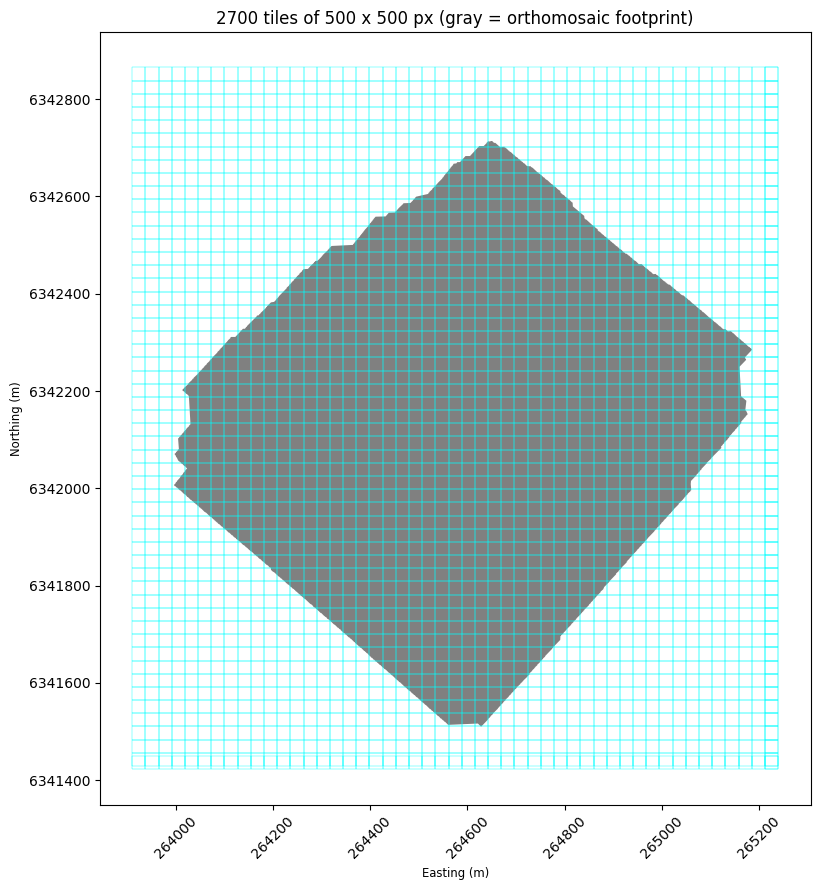

In [29]:
fig, ax = plt.subplots(figsize=(9, 9))
#ax.set_facecolor("#151515")

gpd.GeoSeries([footprint], crs=crs).plot(ax=ax, color="gray")                       # orthomosaic boundary, filled
gpd.GeoSeries([box(*bounds)], crs=crs).boundary.plot(ax=ax, color="white",
                                                     linestyle="--", linewidth=1)   # raster bounding box
grid.boundary.plot(ax=ax, color="cyan", linewidth=0.3)                              # the entire tile grid

ax.set_title(f"{len(grid)} tiles of {TILE} x {TILE} px (gray = orthomosaic footprint)")
ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
ax.ticklabel_format(useOffset=False, style="plain")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [30]:
min_px = int(MIN_STRUCT_M2 / res**2)

def clean_struct(mask):
    mask = ndi.binary_opening(mask, structure=np.ones((3, 3)))     # remove thin noise
    return remove_small_objects(mask, min_size=min_px)

rows = []
todo = grid[grid.has_data]
for t in tqdm(todo.itertuples(), total=len(todo)):
    s = reader.read(t.col_off, t.row_off, t.width, t.height, image=False)
    nd = s["ndsm"]
    fin = np.isfinite(nd)
    m = clean_struct(np.nan_to_num(nd, nan=0.0) > HEIGHT_THR)
    n_valid = int(s["valid"].sum())
    rows.append(dict(tile_id=t.tile_id,
                     valid_frac=n_valid / s["valid"].size,         # exact, full resolution
                     ndsm_cover=fin.sum() / max(n_valid, 1),       # share of valid pixels with an nDSM value
                     struct_px=int(m.sum()),
                     struct_frac=m.sum() / max(n_valid, 1),
                     ndsm_max=float(nd[fin].max()) if fin.any() else np.nan))

stats = pd.DataFrame(rows).set_index("tile_id")
grid = grid.drop(columns=stats.columns, errors="ignore").join(stats)

# group 1: category per tile
has_struct = grid.struct_px.fillna(0) > 0
grid["group"] = np.select([~grid.has_data, has_struct], ["no data", "structures"], default="ground only")

# group 2: clusters of adjacent structure tiles (8-connected on the tile grid)
flag = np.zeros((grid.ri.max() + 1, grid.ci.max() + 1), bool)
flag[grid.ri[has_struct].to_numpy(), grid.ci[has_struct].to_numpy()] = True
lab, n_clusters = ndi.label(flag, structure=np.ones((3, 3)))
grid["cluster"] = lab[grid.ri.to_numpy(), grid.ci.to_numpy()]      # 0 = not a structure tile

print(grid.group.value_counts())
print(n_clusters, "clusters of adjacent structure tiles")
summary = (grid[grid.cluster > 0].groupby("cluster")
           .agg(n_tiles=("tile_id", "size"),
                struct_ha=("struct_px", lambda s: s.sum() * res**2 / 1e4),
                max_height_m=("ndsm_max", "max")).round(2))
print(summary.sort_values("n_tiles", ascending=False).head(15))

  0%|          | 0/1110 [00:00<?, ?it/s]

group
no data        1590
structures     1022
ground only      88
Name: count, dtype: int64
2 clusters of adjacent structure tiles
         n_tiles  struct_ha  max_height_m
cluster                                  
1           1021       20.0         62.43
2              1        0.0          3.03


We can plot the different tile groups.

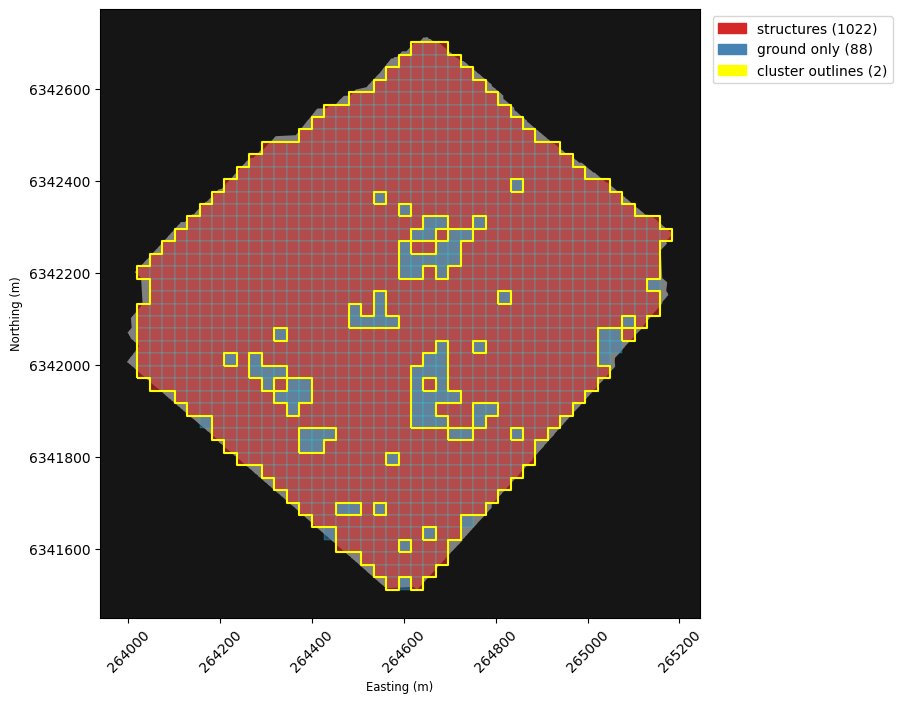

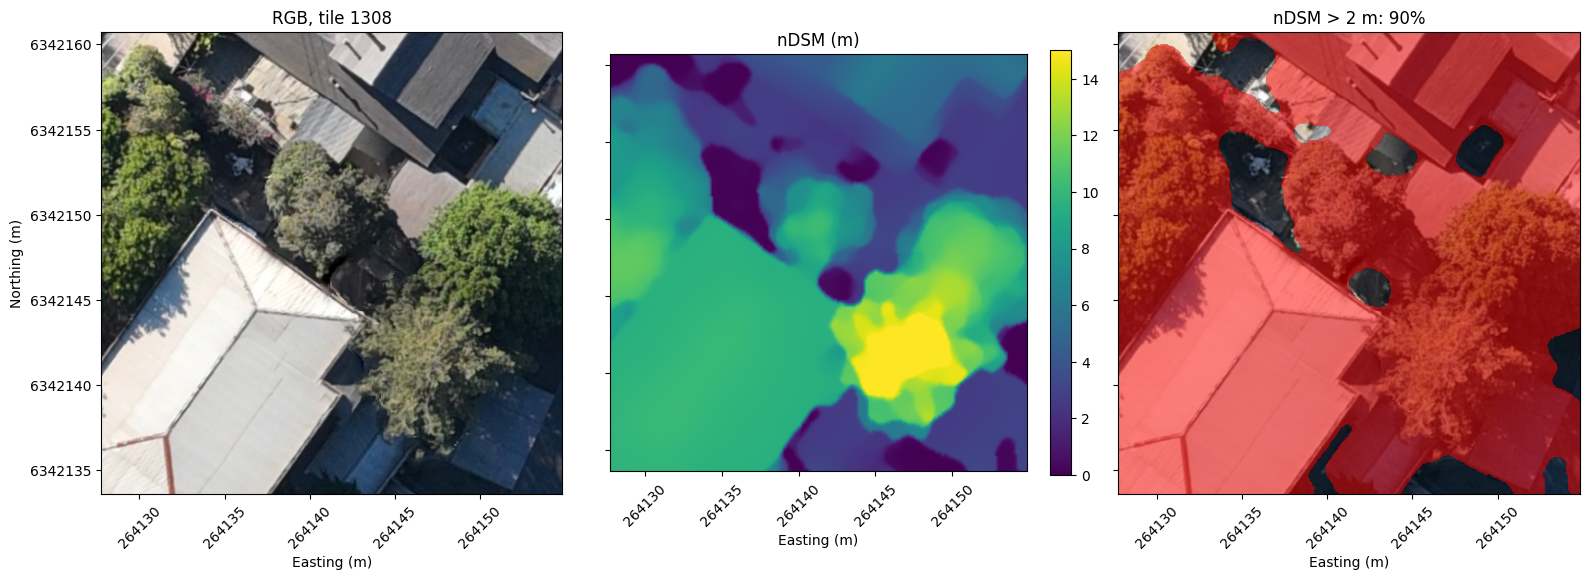

In [37]:
# map of the groups
fig, ax = plt.subplots(figsize=(9, 9))
ax.set_facecolor("#151515")
gpd.GeoSeries([footprint], crs=crs).plot(ax=ax, color="gray")
grid[grid.group == "ground only"].plot(ax=ax, facecolor="steelblue", edgecolor="cyan", alpha=0.5, linewidth=0.3)
grid[grid.group == "structures"].plot(ax=ax, facecolor="tab:red", edgecolor="cyan", alpha=0.6, linewidth=0.3)
if n_clusters:
    grid[grid.cluster > 0].dissolve("cluster").boundary.plot(ax=ax, color="yellow", linewidth=1.5)
ax.legend(handles=[Patch(color="tab:red", label=f"structures ({(grid.group == 'structures').sum()})"),
                   Patch(color="steelblue", label=f"ground only ({(grid.group == 'ground only').sum()})"),
                   Patch(color="yellow", label=f"cluster outlines ({n_clusters})")],
          loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_xlabel("Easting (m)"); ax.set_ylabel("Northing (m)")
ax.ticklabel_format(useOffset=False, style="plain"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()


# one tile: RGB | nDSM | structures above the threshold
def show_tile(tile_id):
    t = grid.loc[tile_id]
    s = reader.read(t.col_off, t.row_off, t.width, t.height)
    m = clean_struct(np.nan_to_num(s["ndsm"], nan=0.0) > HEIGHT_THR)
    l, b, r, tp = t.geometry.bounds
    ext = (l, r, b, tp)
    rgb = s["image"].transpose(1, 2, 0)

    fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharex=True, sharey=True)
    axes[0].imshow(rgb, extent=ext); axes[0].set_title(f"RGB, tile {tile_id}")
    im = axes[1].imshow(s["ndsm"], cmap="viridis", vmin=0, vmax=15, extent=ext)
    axes[1].set_title("nDSM (m)"); plt.colorbar(im, ax=axes[1], fraction=0.046)
    axes[2].imshow(rgb, extent=ext)
    axes[2].imshow(np.ma.masked_where(~m, m), cmap="autumn", alpha=0.5, extent=ext)
    axes[2].set_title(f"nDSM > {HEIGHT_THR:g} m: {m.mean():.0%}")
    for ax in axes:
        ax.set_xlabel("Easting (m)")
        ax.ticklabel_format(useOffset=False, style="plain"); ax.tick_params(axis="x", rotation=45)
    axes[0].set_ylabel("Northing (m)")
    plt.tight_layout(); plt.show()

show_tile(grid[grid.group == "structures"].struct_frac.idxmax())    # the tile with the largest structure share

In [ ]:
# lazy dataset of the structure tiles (nothing is cached; each item is read on demand)
class TileDataset:
    def __init__(self, table, reader):
        self.t, self.reader = table.reset_index(drop=True), reader

    def __len__(self):
        return len(self.t)

    def __getitem__(self, i):
        r = self.t.iloc[i]
        s = self.reader.read(r.col_off, r.row_off, r.width, r.height)   # image, valid, ndsm
        s["mask"] = clean_struct(np.nan_to_num(s["ndsm"], nan=0.0) > HEIGHT_THR)
        s["tile_id"], s["cluster"] = int(r.tile_id), int(r.cluster)
        return s

ds = TileDataset(grid[grid.group == "structures"], reader)
sample = ds[0]          # image (3,500,500) uint8 | valid (500,500) bool | ndsm float32 | mask bool

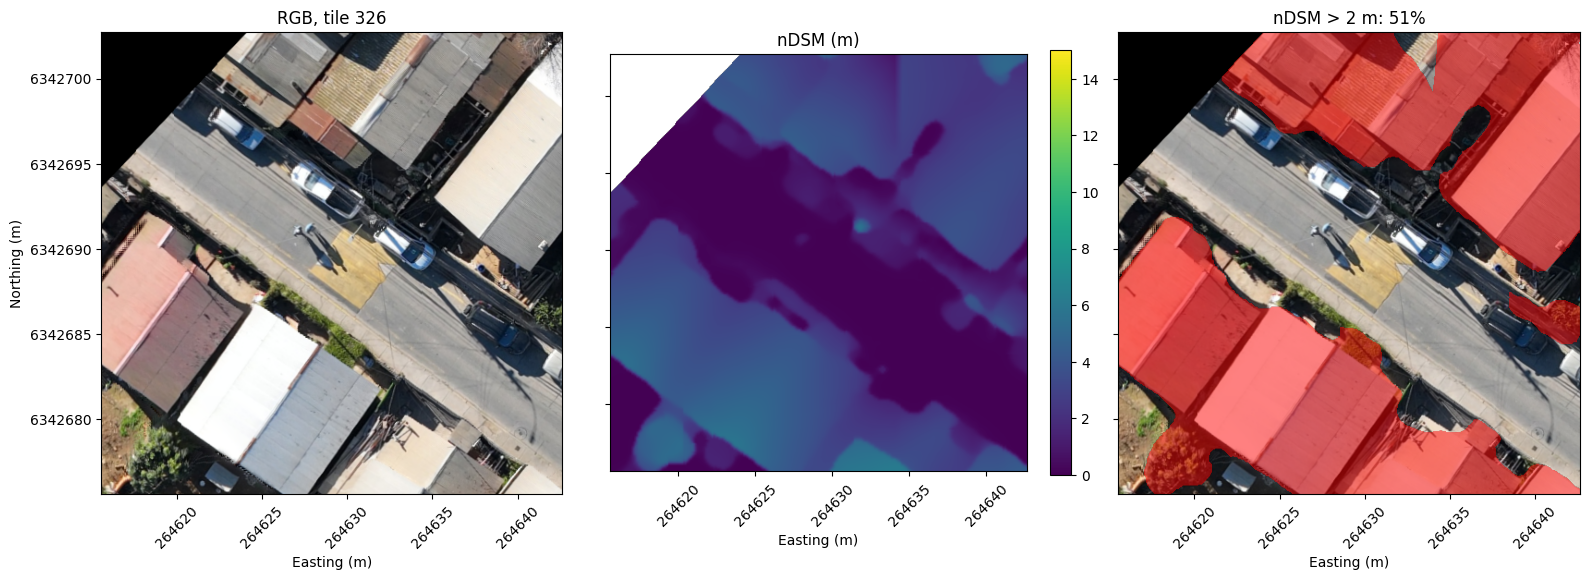

In [55]:
show_tile(sample['tile_id'])

# Creating chips of tiles.